# 04 — Traditional machine learning

This notebook fits two approved models on the Phase 4 chronological partitions: logistic regression, and histogram gradient boosting. A dense random forest is not used. The one-hot matrix is sparse, and a dense copy would be too large for this environment.

The preprocessor and the categorical codes are fit on the training period only. Validation rows are not resampled. The locked test partition is counted and then left untouched. No champion is chosen here; notebook 05 adds the neural models and makes that comparison on validation macro-F1.


## 1. Setup


In [1]:
from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning

cwd = Path.cwd().resolve()
project_root = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "src" / "config.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Start JupyterLab from the project folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.evaluation import classification_scores, probability_summary
from src.preprocessing import (
    SOURCE_CATEGORICAL_COLUMNS,
    build_baseline_preprocessor,
    chronological_splits,
    logging_feature_frame,
    make_logistic_baseline,
)
from src.training import (
    APPROVED_APPROVAL,
    HIST_GRADIENT_BOOSTING_PARAMETERS,
    TreeCategoryEncoder,
    balanced_class_weights,
    describe_sparse_matrix,
    make_hist_gradient_boosting,
    probabilities_in_label_order,
    save_json,
    summarise_predictions,
    use_best_validation_iteration,
)
from src.visualization import plot_boosting_curve, plot_confusion_matrix

config.set_random_seeds()
print(f"Project root: {config.PROJECT_ROOT}")
print(f"Random seed: {config.RANDOM_SEED}")
print("Locked test scoring in this notebook: no")


Project root: /workspace
Random seed: 42
Locked test scoring in this notebook: no


## 2. The same partitions

Training ends on 31 December 2024, validation ends on 31 December 2025, and the locked test ends on 30 April 2026. These dates were fixed in Phase 4, before this notebook fitted a model. January 2025 has no created requests, so the first validation row is in February.


In [2]:
source_columns = list(SOURCE_CATEGORICAL_COLUMNS) + ["Created_On_Date", "resolution_outcome"]
frame = pd.read_parquet(
    config.PROCESSED_DATA_DIR / "service_requests_labelled.parquet",
    columns=source_columns,
)
splits, split_summary, exclusions = chronological_splits(frame)
del frame
# The locked test remains in the summary so its size is visible. It is not encoded or scored.
test_rows = int(split_summary.loc[split_summary["split"].eq("test"), "rows"].iloc[0])
del splits["test"]

X_train = logging_feature_frame(splits["train"])
X_validation = logging_feature_frame(splits["validation"])
y_train = splits["train"]["resolution_outcome"].to_numpy()
y_validation = splits["validation"]["resolution_outcome"].to_numpy()
del splits

display(split_summary)
display(exclusions)
print(f"Locked test rows held out of this notebook: {test_rows:,}")
print(f"Training rows: {len(X_train):,}. Validation rows: {len(X_validation):,}.")
print("Predictors:", ", ".join(X_train.columns))


,split,rows,start_date,end_date,Resolved Fast,Resolved Slow,Unresolved,Resolved Fast percent,Resolved Slow percent,Unresolved percent
0,train,2616595,2023-01-01,2024-12-31,1730948,767337,118310,66.152691,29.325784,4.521525
1,validation,936469,2025-02-01,2025-12-31,648570,88411,199488,69.256964,9.440889,21.302147
2,test,422033,2026-01-01,2026-04-30,287131,65522,69380,68.035201,15.525326,16.439473


,reason,rows
0,unlabelled_or_missing_created_date,16001
1,labelled_after_mature_end,601705
2,train,2616595
3,validation,936469
4,test,422033


Locked test rows held out of this notebook: 422,033
Training rows: 2,616,595. Validation rows: 936,469.
Predictors: C3_Complaint_Type, Suburb, Ward, Sub_Council, created_day_of_week, created_month, created_is_weekend


## 3. One-hot encoding and tree codes

Complaint type and suburb have thousands of training levels. The one-hot pipeline keeps a level with at least 200 training rows, imputes blanks as `(missing)`, and ignores levels that were not in training. That sparse matrix is the input to logistic regression and, in the next notebook, to the multilayer perceptron.

Histogram gradient boosting accepts at most 255 categories in a column. The tree encoder therefore keeps at most 253 frequent training levels, leaving room for `(rare)` and `(missing)`. A level that was too rare, and a level that first appears after training, uses the trained rare code when that code exists. This cap is the library limit. It was not chosen by searching validation scores.

Class imbalance is handled with balanced class weights from the training counts. SMOTE is not used. Applying it to raw category strings would invent combinations that were never logged, and the validation rows are not resampled.


In [3]:
preprocessor = build_baseline_preprocessor()
started = time.perf_counter()
preprocessor.fit(X_train)
X_train_encoded = preprocessor.transform(X_train)
X_validation_encoded = preprocessor.transform(X_validation)
print(f"One-hot fit and transform seconds: {time.perf_counter() - started:.1f}")

one_hot = describe_sparse_matrix(X_train_encoded, "train")
one_hot_validation = describe_sparse_matrix(X_validation_encoded, "validation")
rare_summary = preprocessor.named_transformers_["categorical"].named_steps["rare"].rare_summary()
display(rare_summary)
print(
    f"Training one-hot matrix: {one_hot['rows']:,} rows, {one_hot['columns']:,} columns, "
    f"{one_hot['nonzero']:,} stored values."
)
print(f"A dense float32 copy of the training matrix would be {one_hot['dense_float32_gib']:.1f} GiB.")
print(
    "One-hot encoding is practical for logistic regression and the multilayer perceptron. "
    "The tree model uses native categorical codes so it does not materialise that dense matrix."
)

tree_encoder = TreeCategoryEncoder().fit(X_train)
tree_levels = tree_encoder.level_summary()
display(tree_levels)
if int(tree_levels["encoded_levels"].max()) > 255:
    raise RuntimeError("A tree column still exceeds the 255-category booster limit.")

weights = balanced_class_weights(y_train)
class_weight_table = pd.DataFrame(
    {
        "label": list(config.TARGET_LABELS),
        "training_rows": [int(np.sum(y_train == label)) for label in config.TARGET_LABELS],
        "balanced_weight": weights,
    }
)
display(class_weight_table.round(3))
print("Imbalance method: balanced class weights. SMOTE: not used. Validation resampled: no.")


One-hot fit and transform seconds: 9.5


,column,training_rows,distinct_categories,kept_categories,grouped_categories,min_count,kept_row_percent
0,C3_Complaint_Type,2616595,998,372,626,200,99.052700
1,Suburb,2616595,28394,1080,27314,200,95.208926
2,Ward,2616595,219,218,1,200,99.995108
3,Sub_Council,2452537,32,23,9,200,99.986300
4,created_day_of_week,2616595,7,7,0,200,100.000000
5,created_month,2616595,12,12,0,200,100.000000


Training one-hot matrix: 2,616,595 rows, 1,718 columns, 18,316,165 stored values.
A dense float32 copy of the training matrix would be 16.7 GiB.
One-hot encoding is practical for logistic regression and the multilayer perceptron. The tree model uses native categorical codes so it does not materialise that dense matrix.


,column,distinct_training_levels,kept_levels,grouped_levels,missing_training_rows,encoded_levels,min_count,max_kept
0,C3_Complaint_Type,998,253,745,0,254,200,253
1,Suburb,28394,253,28141,0,254,200,253
2,Ward,219,218,1,0,219,200,253
3,Sub_Council,32,23,9,164058,25,200,253
4,created_day_of_week,7,7,0,0,7,200,253
5,created_month,12,12,0,0,12,200,253


,label,training_rows,balanced_weight
0,Resolved Fast,1730948,0.504
1,Resolved Slow,767337,1.137
2,Unresolved,118310,7.372


Imbalance method: balanced class weights. SMOTE: not used. Validation resampled: no.


## 4. Logistic regression

This is the Phase 4 interpretable baseline: L2-regularised saga logistic regression, C = 1, balanced class weights, at most 200 iterations, and tolerance 0.001. Those settings were not retuned on the validation score. The solver may stop at the iteration cap. The probabilities are checked after fitting, and both the training period and the validation period are scored.


Logistic fit seconds: 223.3
Iterations used: 200
Convergence warning: True
Validation probability columns: Resolved Fast, Resolved Slow, Unresolved
Row sums on the first 5,000 validation rows: 1.000000 to 1.000000
Scoring logistic_regression on train...


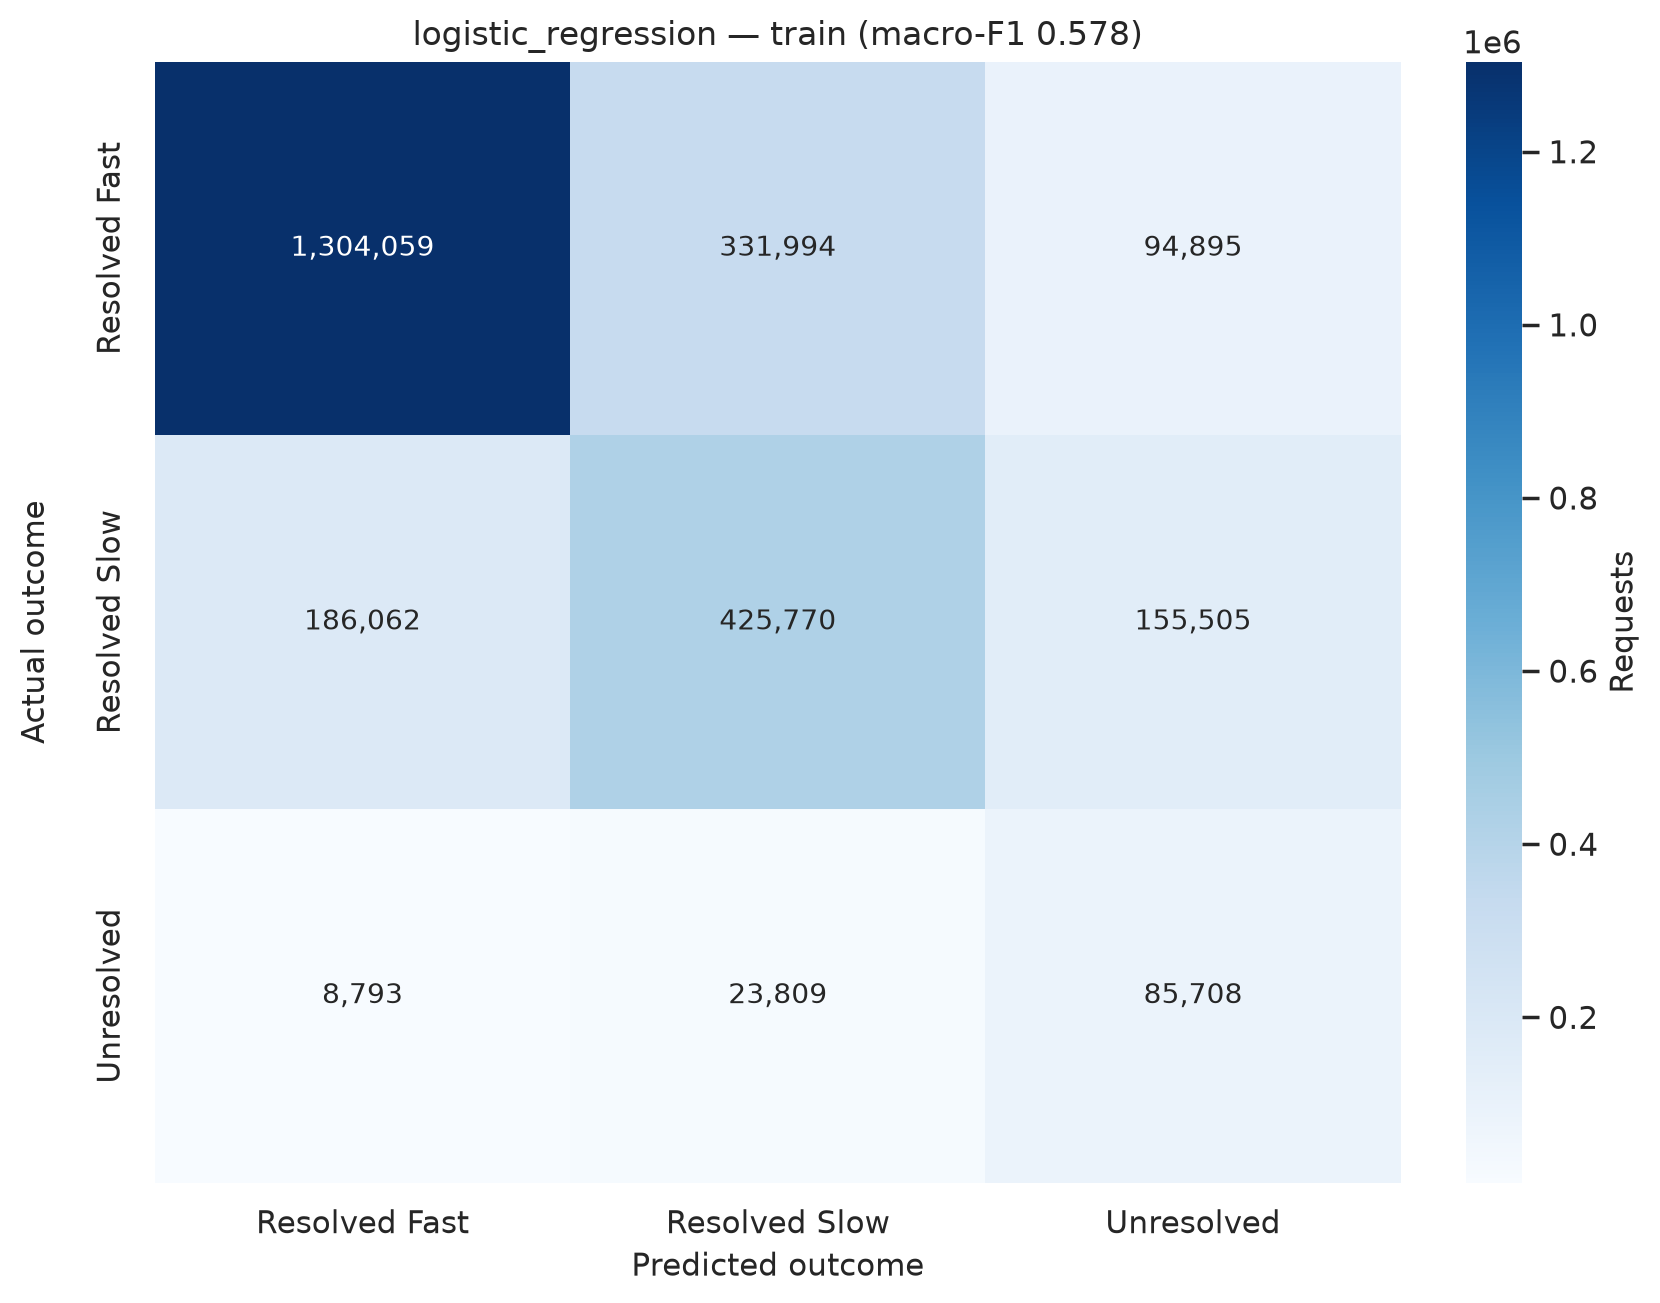

Scoring logistic_regression on validation...


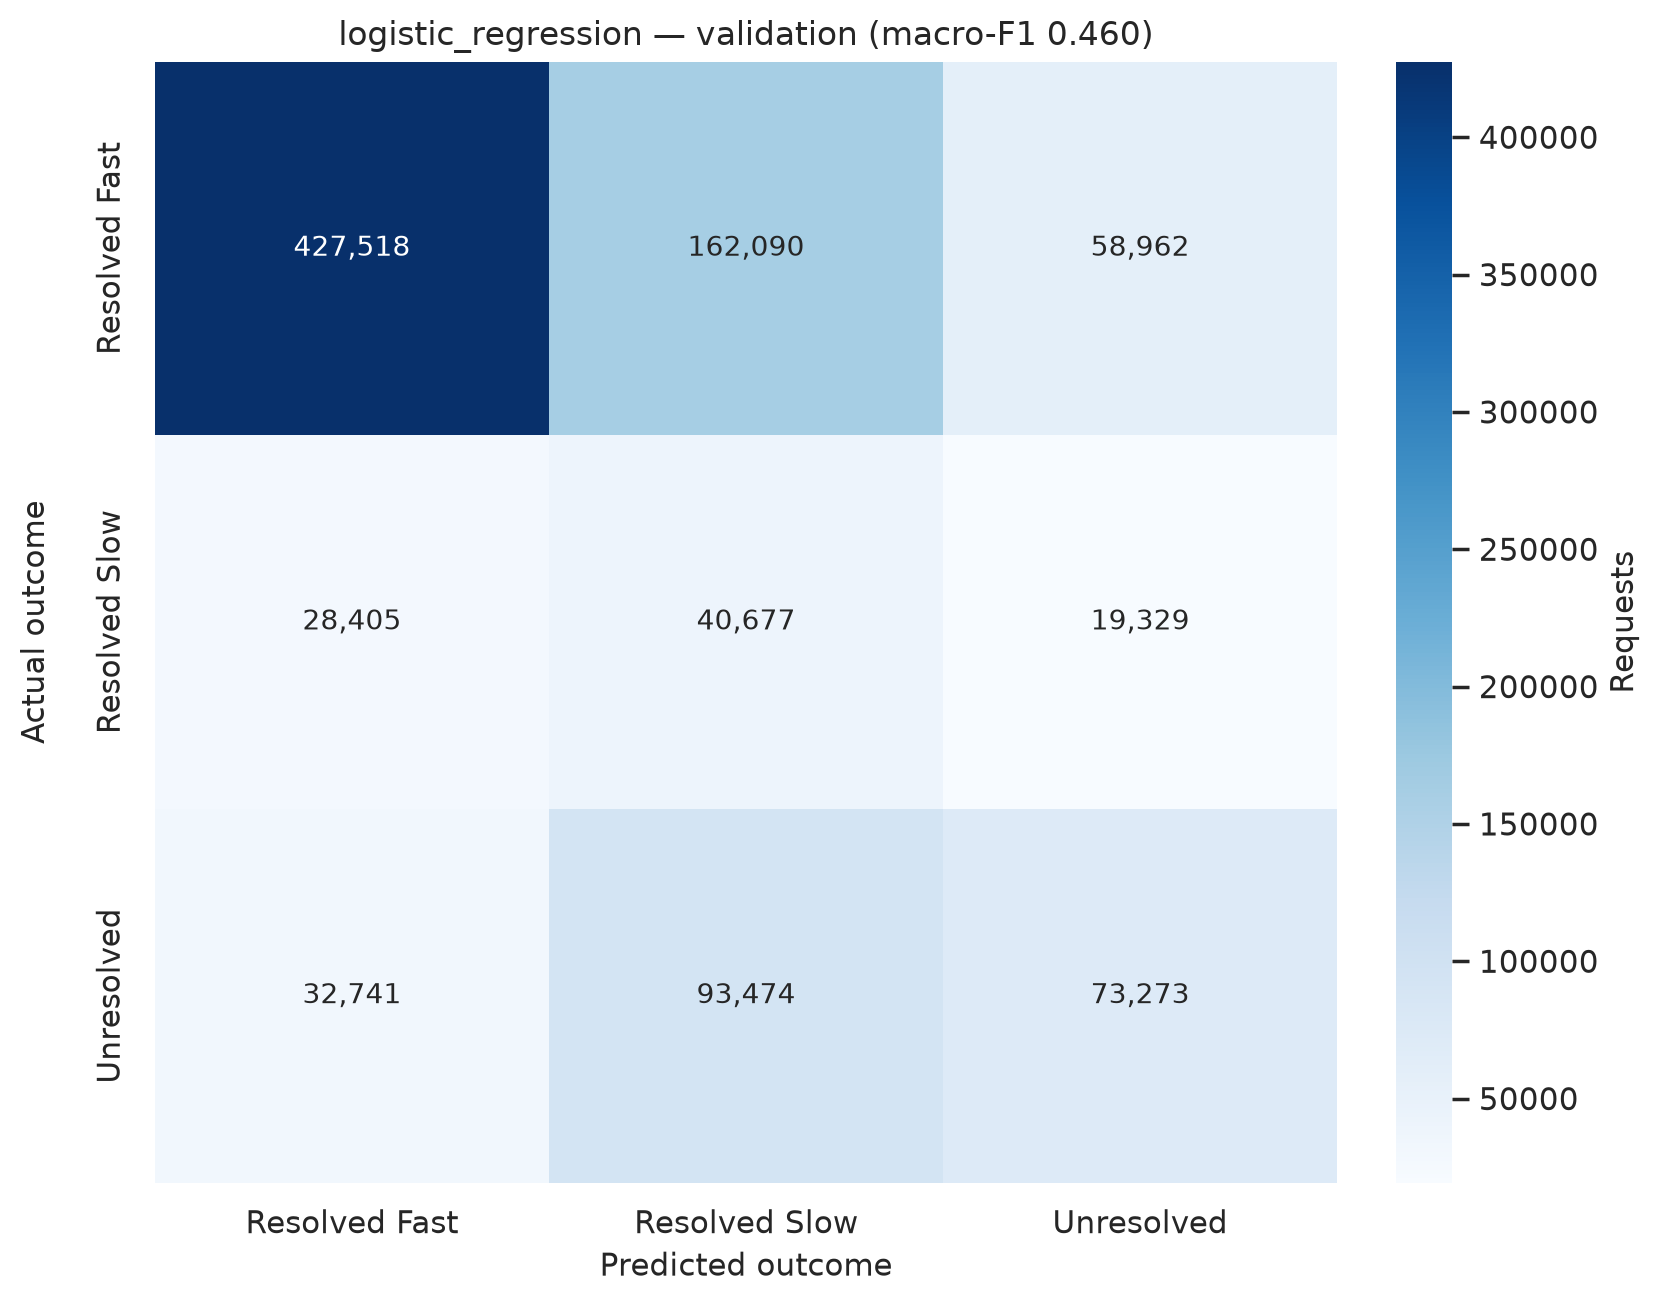

In [4]:
logistic = make_logistic_baseline()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    started = time.perf_counter()
    logistic.fit(X_train_encoded, y_train)
    logistic_seconds = time.perf_counter() - started
logistic_warning = any(issubclass(item.category, ConvergenceWarning) for item in caught)
logistic_iterations = int(np.max(logistic.n_iter_))
print(f"Logistic fit seconds: {logistic_seconds:.1f}")
print(f"Iterations used: {logistic_iterations}")
print(f"Convergence warning: {logistic_warning}")
probability_check = probability_summary(logistic, X_validation_encoded[:5000])
print(
    "Validation probability columns:",
    ", ".join(probability_check["classes"]),
)
print(
    f"Row sums on the first 5,000 validation rows: "
    f"{probability_check['row_sum_min']:.6f} to {probability_check['row_sum_max']:.6f}"
)


def score_estimator(model, features, labels, model_name, fit_seconds, split):
    print(f"Scoring {model_name} on {split}...", flush=True)
    predicted = model.predict(features)
    probabilities = probabilities_in_label_order(model.predict_proba(features), model.classes_)
    summary, per_class = summarise_predictions(
        labels,
        predicted,
        probabilities,
        model=model_name,
        split=split,
        approval=APPROVED_APPROVAL,
        fit_seconds=fit_seconds,
    )
    scores = classification_scores(labels, predicted)
    title = f"{model_name} — {split} (macro-F1 {scores['macro_f1']:.3f})"
    _figure, path = plot_confusion_matrix(
        scores["confusion_matrix"],
        list(config.TARGET_LABELS),
        title,
        f"05_confusion_{model_name}_{split}.png",
    )
    return summary, per_class, path


logistic_summaries = []
logistic_classes = []
for split_name, features, labels in (
    ("train", X_train_encoded, y_train),
    ("validation", X_validation_encoded, y_validation),
):
    summary, per_class, path = score_estimator(
        logistic, features, labels, "logistic_regression", logistic_seconds, split_name
    )
    logistic_summaries.append(summary)
    logistic_classes.append(per_class)
    display(Image(filename=str(path)))

# The encoded matrices are only needed for the linear model.
del X_train_encoded, X_validation_encoded, logistic


## 5. Histogram gradient boosting

The booster is an approved traditional model. It uses log loss, a learning rate of 0.1, at most 31 leaves, a minimum of 50 samples per leaf, L2 regularisation of 1, and balanced class weights. Early stopping watches macro-F1 on the chronological validation period. It does not draw a random subset out of the training rows.

The library keeps a few trees after the best validation score. Predictions in this notebook use the iteration with the highest validation macro-F1. The per-iteration training score stored by the library is a 10,000-row subset. The training macro-F1 in the table is computed on the full training period after that iteration has been selected.


Boosting fit seconds: 17.7
Iterations trained: 8
Iteration used for predictions: 2
Reached the iteration cap: False
Early-stopping validation macro-F1 at the selected iteration: 0.482


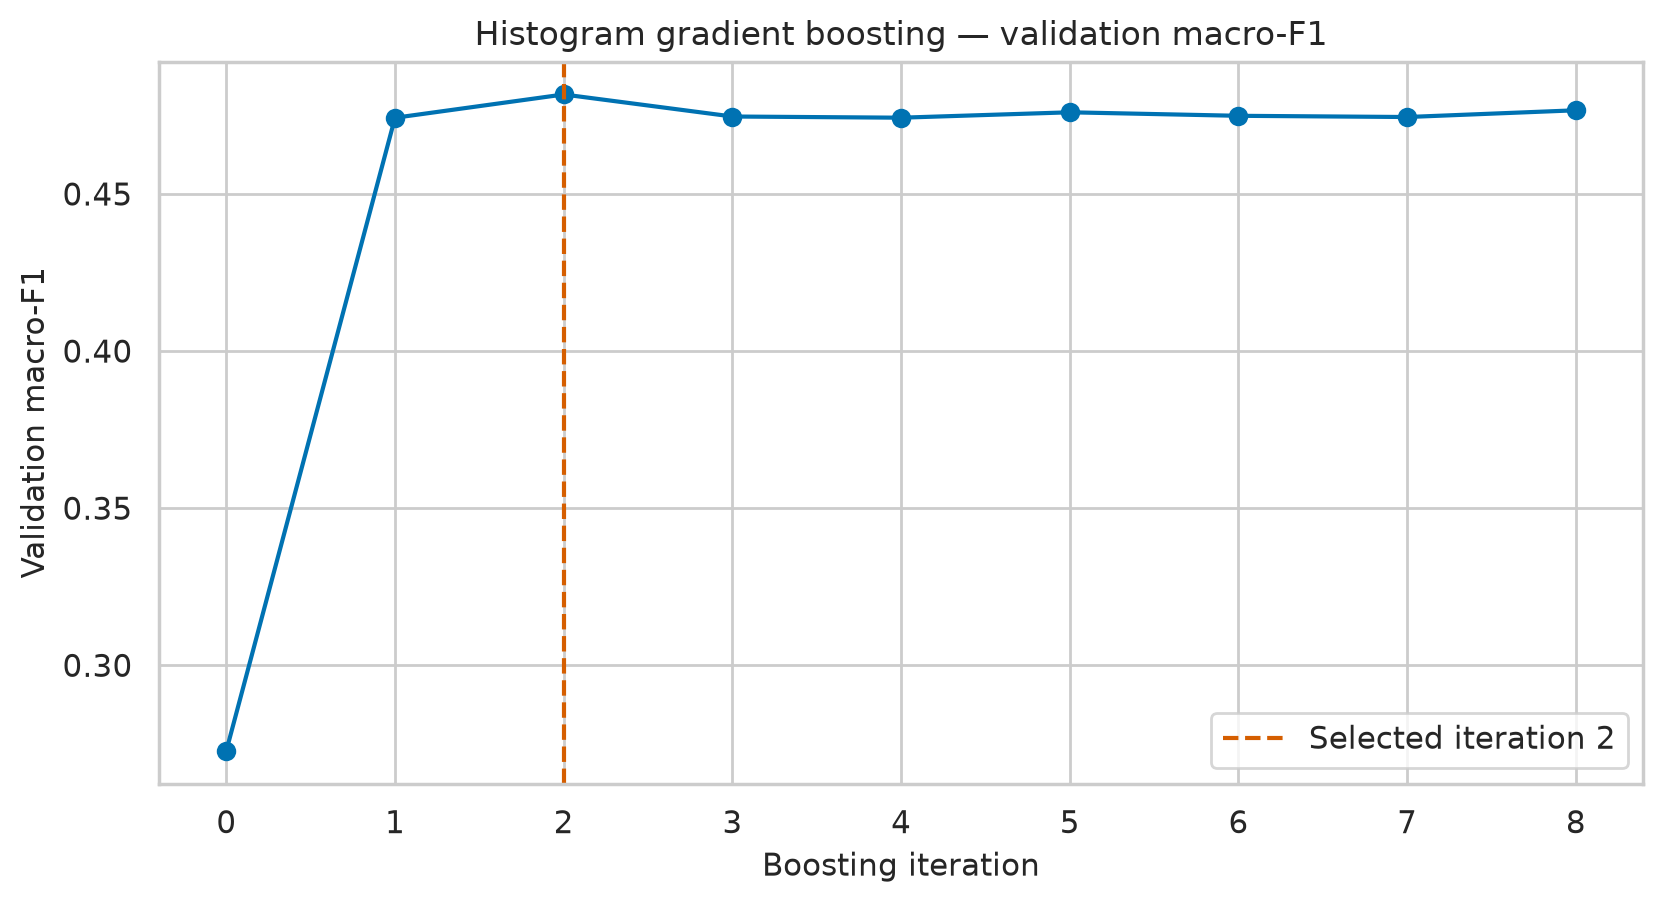

Scoring hist_gradient_boosting on train...


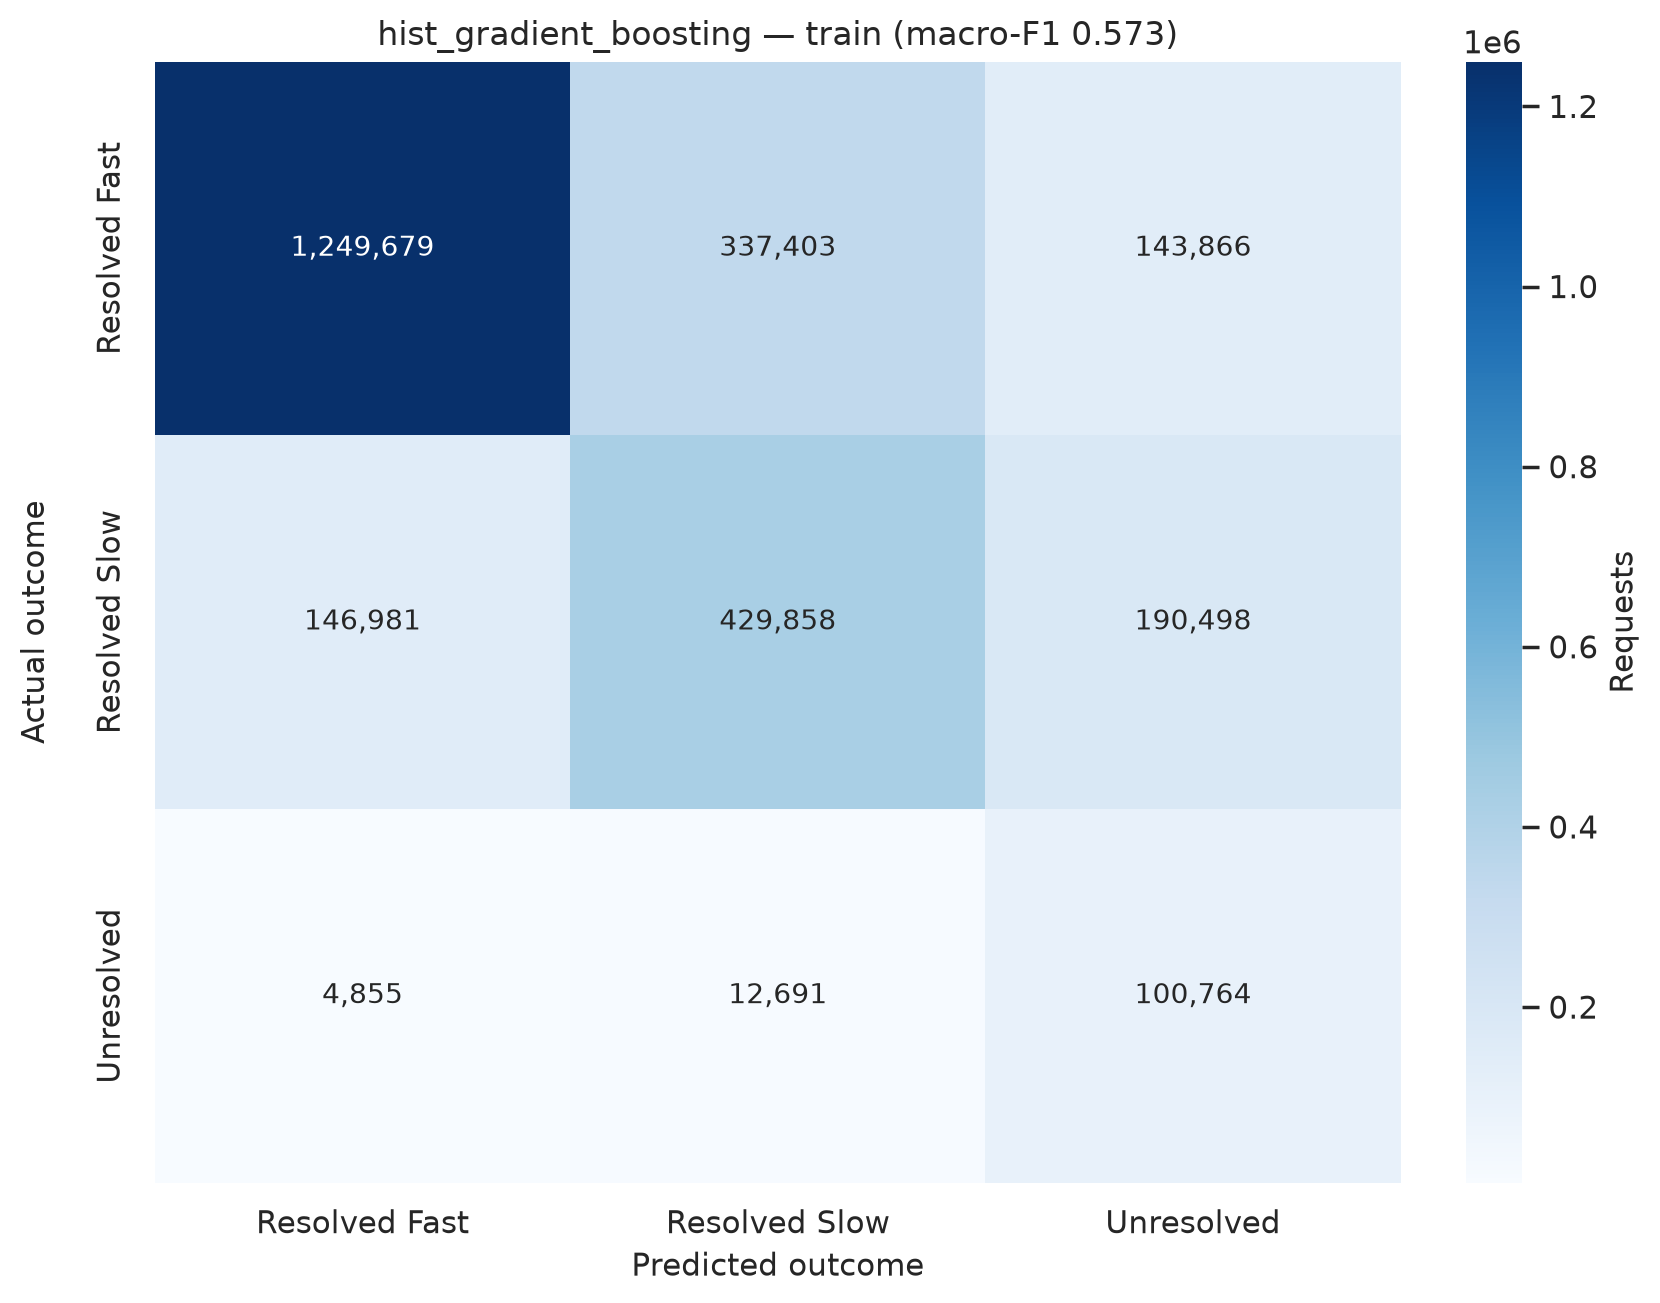

Scoring hist_gradient_boosting on validation...


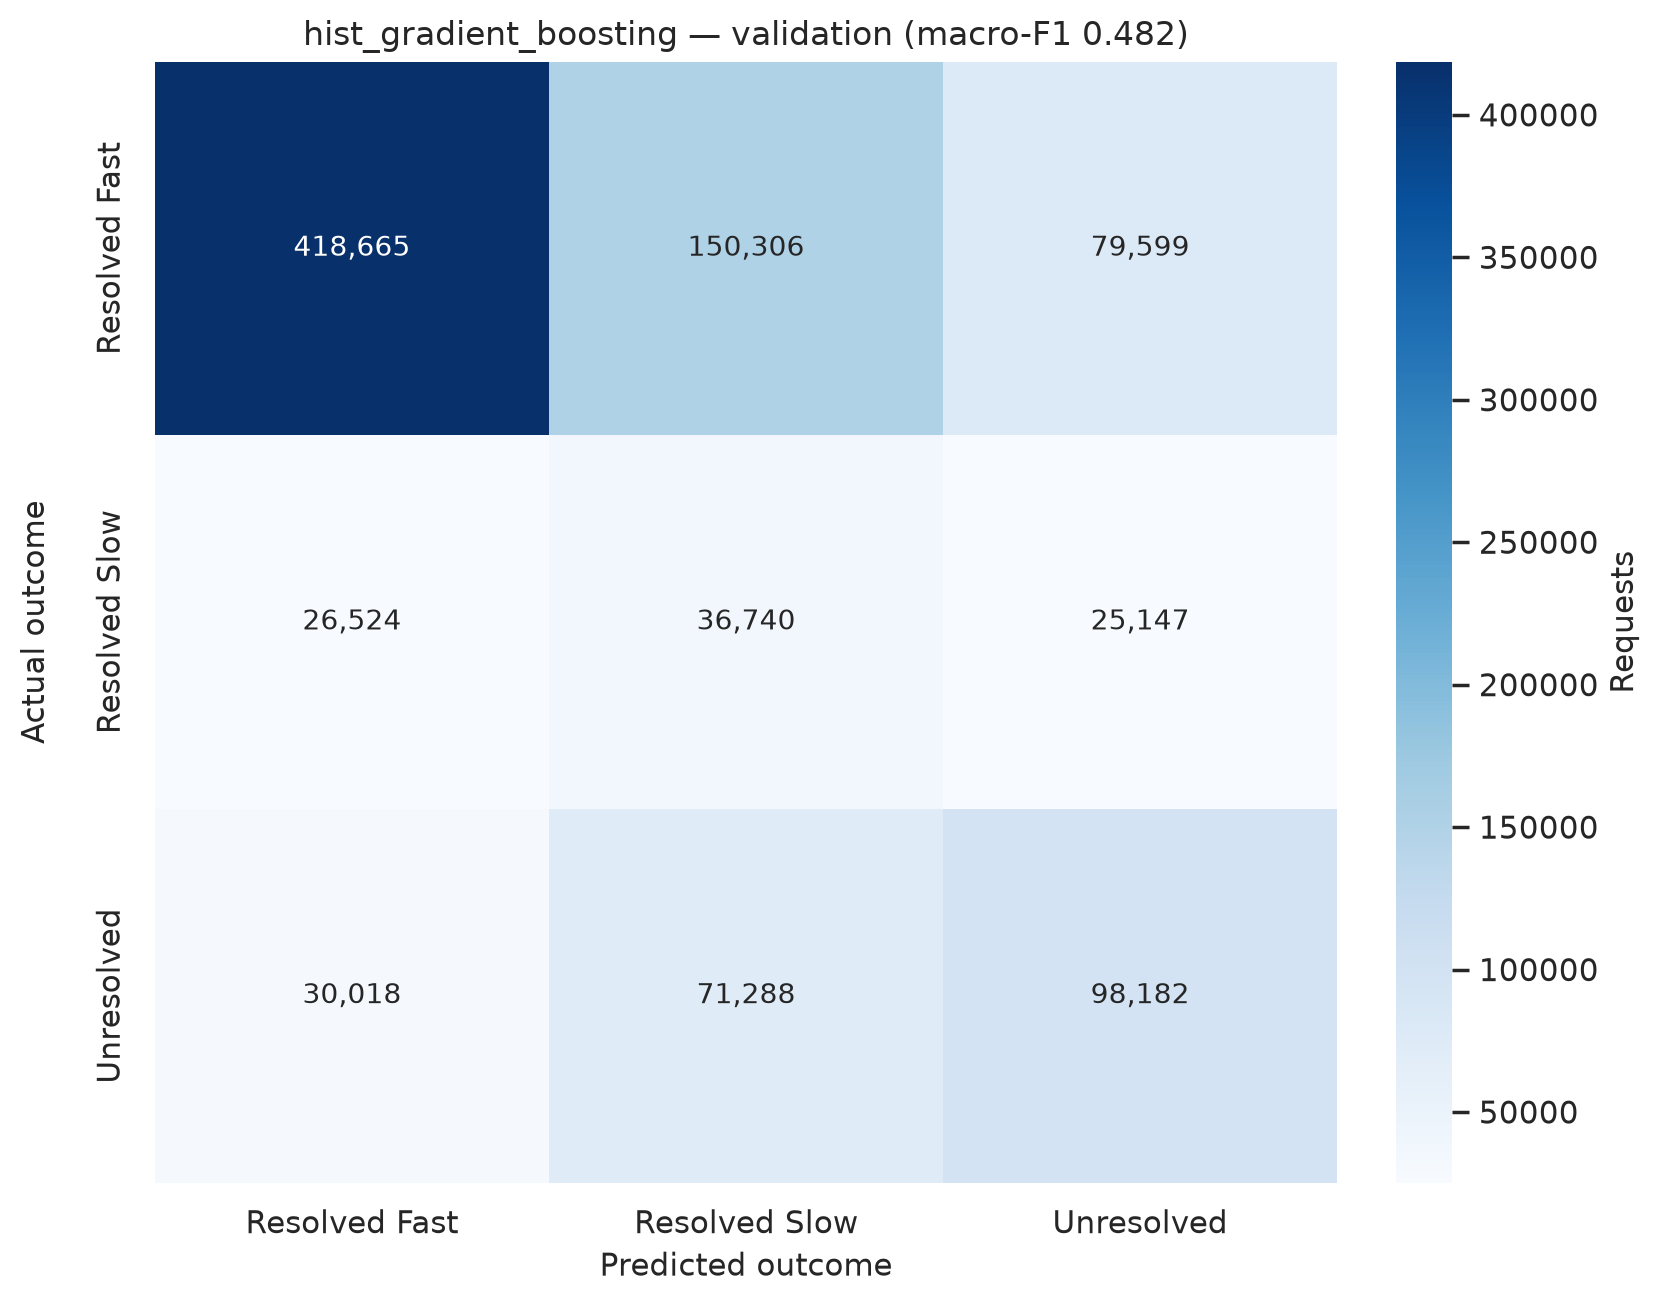

In [5]:
X_train_tree = tree_encoder.transform(X_train)
X_validation_tree = tree_encoder.transform(X_validation)
booster = make_hist_gradient_boosting()
started = time.perf_counter()
booster.fit(X_train_tree, y_train, X_val=X_validation_tree, y_val=y_validation)
boosting_seconds = time.perf_counter() - started
boosting_curve = pd.DataFrame(
    {
        "iteration": np.arange(len(booster.validation_score_)),
        "validation_macro_f1": np.asarray(booster.validation_score_, dtype=float),
        "train_subset_macro_f1": np.asarray(booster.train_score_, dtype=float),
    }
)
best_iteration = use_best_validation_iteration(booster)
n_iter_trained = int(booster.n_iter_trained_)
hit_max_iter = n_iter_trained >= int(HIST_GRADIENT_BOOSTING_PARAMETERS["max_iter"])
print(f"Boosting fit seconds: {boosting_seconds:.1f}")
print(f"Iterations trained: {n_iter_trained}")
print(f"Iteration used for predictions: {best_iteration}")
print(f"Reached the iteration cap: {hit_max_iter}")
print(
    "Early-stopping validation macro-F1 at the selected iteration: "
    f"{float(boosting_curve.loc[boosting_curve['iteration'].eq(best_iteration), 'validation_macro_f1'].iloc[0]):.3f}"
)
_figure, curve_path = plot_boosting_curve(
    boosting_curve,
    best_iteration,
    "Histogram gradient boosting — validation macro-F1",
    "05_boosting_validation_curve.png",
)
display(Image(filename=str(curve_path)))

boosting_summaries = []
boosting_classes = []
for split_name, features, labels in (
    ("train", X_train_tree, y_train),
    ("validation", X_validation_tree, y_validation),
):
    summary, per_class, path = score_estimator(
        booster, features, labels, "hist_gradient_boosting", boosting_seconds, split_name
    )
    boosting_summaries.append(summary)
    boosting_classes.append(per_class)
    display(Image(filename=str(path)))


## 6. Training, validation, and saved settings

The comparison below is the full training period against the 2025 validation period. Notebook 05 reads these tables, adds the neural models, and chooses a provisional champion from validation macro-F1. This notebook does not score the locked test and does not rank a winner.


In [6]:
traditional_summary = pd.concat(logistic_summaries + boosting_summaries, ignore_index=True)
traditional_per_class = pd.concat(logistic_classes + boosting_classes, ignore_index=True)
display(traditional_summary.round(3))
display(traditional_per_class.round(3))

config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
traditional_summary.to_csv(config.TABLES_DIR / "05_traditional_summary.csv", index=False)
traditional_per_class.to_csv(config.TABLES_DIR / "05_traditional_per_class.csv", index=False)
rare_summary.to_csv(config.TABLES_DIR / "05_one_hot_rare_summary.csv", index=False)
tree_levels.to_csv(config.TABLES_DIR / "05_tree_category_levels.csv", index=False)
class_weight_table.to_csv(config.TABLES_DIR / "05_class_weights.csv", index=False)
boosting_curve.to_csv(config.TABLES_DIR / "05_boosting_curve.csv", index=False)
split_summary.to_csv(config.TABLES_DIR / "05_split_summary.csv", index=False)
pd.DataFrame([one_hot, one_hot_validation]).to_csv(
    config.TABLES_DIR / "05_one_hot_matrix.csv", index=False
)

selected_curve = float(
    boosting_curve.loc[boosting_curve["iteration"].eq(best_iteration), "validation_macro_f1"].iloc[0]
)
run_notes = {
    "one_hot": one_hot,
    "logistic_regression": {
        "max_iter": int(make_logistic_baseline().max_iter),
        "tol": float(make_logistic_baseline().tol),
        "fit_seconds": float(logistic_seconds),
        "n_iter": logistic_iterations,
        "convergence_warning": bool(logistic_warning),
    },
    "hist_gradient_boosting": {
        "fit_seconds": float(boosting_seconds),
        "n_iter_trained": n_iter_trained,
        "best_iteration": int(best_iteration),
        "validation_macro_f1_at_best": selected_curve,
        "hit_max_iter": bool(hit_max_iter),
    },
}
save_json(run_notes, config.TABLES_DIR / "05_traditional_run.json")
print("Saved traditional metrics and the run notes. The locked test was not scored.")
print("Notebook 05 chooses the provisional champion after the neural models have been fit.")


,model,split,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved,macro_roc_auc,macro_average_precision,approval,fit_seconds
0,logistic_regression,train,0.694,0.578,0.712,0.753,0.555,0.724,0.845,0.626,approved,223.251
1,logistic_regression,validation,0.578,0.460,0.630,0.659,0.460,0.367,0.729,0.496,approved,223.251
2,hist_gradient_boosting,train,0.680,0.573,0.707,0.722,0.560,0.852,0.858,0.651,approved,17.734
3,hist_gradient_boosting,validation,0.591,0.482,0.640,0.646,0.416,0.492,0.739,0.506,approved,17.734


,model,split,label,precision,recall,f1,support
0,logistic_regression,train,Resolved Fast,0.870,0.753,0.808,1730948
1,logistic_regression,train,Resolved Slow,0.545,0.555,0.550,767337
2,logistic_regression,train,Unresolved,0.255,0.724,0.377,118310
3,logistic_regression,validation,Resolved Fast,0.875,0.659,0.752,648570
4,logistic_regression,validation,Resolved Slow,0.137,0.460,0.212,88411
5,logistic_regression,validation,Unresolved,0.483,0.367,0.417,199488
6,hist_gradient_boosting,train,Resolved Fast,0.892,0.722,0.798,1730948
7,hist_gradient_boosting,train,Resolved Slow,0.551,0.560,0.556,767337
8,hist_gradient_boosting,train,Unresolved,0.232,0.852,0.364,118310
9,hist_gradient_boosting,validation,Resolved Fast,0.881,0.646,0.745,648570


Saved traditional metrics and the run notes. The locked test was not scored.
Notebook 05 chooses the provisional champion after the neural models have been fit.
